In [1]:
# -*- coding: utf-8 -*-

Comparing Machine Learning Methods.ipynb

Automatically generated by Colaboratory.

Original file is located at
    https://colab.research.google.com/drive/11VDNoEPj8KgT3KxssfDtcsZpmUKlv9YF

Refernce:
https://pythondata.com/category/machine-learning/

https://machinelearningmastery.com/compare-machine-learning-algorithms-python-scikit-learn/

# Initialization

In [2]:
# from google.colab import drive
# drive.mount('/content/drive')

# import os
# os.chdir("/content/drive/My Drive/ComparingMachineLearningMethods/")
# !ls

This is a tutorial on how to compare machine learning methods with the python library scikit-learn. We'll be using the Indian Liver Disease dataset (found here https://www.kaggle.com/uciml/indian-liver-patient-records).

From the dataset page:

"This data set contains 416 liver patient records and 167 non liver patient records collected from North East of Andhra Pradesh, India. The "Dataset" column is a class label used to divide groups into liver patient (liver disease) or not (no disease). This data set contains 441 male patient records and 142 female patient records."

I've used Jason Brownlee's article (https://machinelearningmastery.com/compare-machine-learning-algorithms-python-scikit-learn/) from 2016 as the basis for this article...I wanted to expand a bit on what he did as well as use a different dataset.

In [1]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (20,10)

from pandas.plotting import scatter_matrix

from sklearn import model_selection
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import numpy as np

# Load Machine Learning Data

In [3]:
#read in the data
data = pd.read_csv('HCV-Egy-Data.csv')
# Target = last column (histological staging, F1-F4). Advanced fibrosis = stage F3/F4 -> 1, else 0.
data.iloc[:, -1] = (data.iloc[:, -1] >= 3).astype(int)
print(data.shape)

# #read in the data
# data = pd.read_csv('HCV-Egy-Data.csv')

(1385, 29)


# Understand Your Data With Descriptive Statistics

You must understand your data in order to get the best results. We will discover
7 recipes that you can use in Python to better understand your machine learning data. After
reading this lesson you will know how to:

1. Take a peek at your raw data.
2. Review the dimensions of your dataset.
3. Review the data types of attributes in your data.
4. Summarize the distribution of instances across classes in your dataset.
5. Summarize your data using descriptive statistics.
6. Understand the relationships in your data using correlations.
7. Review the skew of the distributions of each attribute.

In [4]:
#1. Peek at Your Data
#review the first 20 rows
data.head(20)

peek = data.head(20)
print(peek)

    Age   Gender  BMI  Fever  Nausea/Vomting  Headache   Diarrhea   \
0     56       1   35      2               1          1          1   
1     46       1   29      1               2          2          1   
2     57       1   33      2               2          2          2   
3     49       2   33      1               2          1          2   
4     59       1   32      1               1          2          1   
5     58       2   22      2               2          2          1   
6     42       2   26      1               1          2          2   
7     48       2   30      1               1          2          2   
8     44       1   23      1               1          2          2   
9     45       1   30      2               1          2          2   
10    37       2   24      2               1          2          1   
11    36       1   22      2               2          1          1   
12    45       2   25      2               1          1          1   
13    34       1   2

We'll use all columns except Gender for this tutorial. We could use gender by converting the gender to a numeric value (e.g., 0 for Male, 1 for Female) but for the purproses of this post, we'll just skip this column.

In [5]:
data_to_use = data
# Gender is already numerically encoded in this dataset, so it is kept
data_to_use.dropna(inplace=True)
# print(data_to_use.shape)

# data_to_use = data
# # # Gender is already numerically encoded in this dataset, so it is kept
# # data_to_use.dropna(inplace=True)

peek = data_to_use.head(20)
print(peek)

    Age   Gender  BMI  Fever  Nausea/Vomting  Headache   Diarrhea   \
0     56       1   35      2               1          1          1   
1     46       1   29      1               2          2          1   
2     57       1   33      2               2          2          2   
3     49       2   33      1               2          1          2   
4     59       1   32      1               1          2          1   
5     58       2   22      2               2          2          1   
6     42       2   26      1               1          2          2   
7     48       2   30      1               1          2          2   
8     44       1   23      1               1          2          2   
9     45       1   30      2               1          2          2   
10    37       2   24      2               1          2          1   
11    36       1   22      2               2          1          1   
12    45       2   25      2               1          1          1   
13    34       1   2

The 'Dataset' column is the value we are trying to predict...whether the user has liver disease or not so we'll that as our "Y" and the other columns for our "X" array.

In [8]:
#2.Dimensions of Your Data
print(data_to_use.shape)

#3.Data Type For Each Attribute
types = data_to_use.dtypes
print(types)

#4.Descriptive Statistics
# Descriptive statistics can give you great insight into the shape of each attribute. Often you can
# create more summaries than you have time to review. The describe() function on the Pandas
# DataFrame lists 8 statistical properties of each attribute. They are:
#  Count.
#  Mean.
#  Standard Deviation.
#  Minimum Value.
#  25th Percentile.
#  50th Percentile (Median).
#  75th Percentile.
#  Maximum Value.

pd.set_option('display.width', 100)
pd.set_option('display.precision', 3)
description = data.describe()
print(description)

data.describe()

# 5.Class Distribution (Classification Only)
class_counts = data_to_use.groupby(data_to_use.columns[-1]).size()
print(class_counts)

# 6.Correlations Between Attributes
# Correlation refers to the relationship between two variables and how they may or may not
# change together. The most common method for calculating correlation is Pearson's Correlation
# Coecient, that assumes a normal distribution of the attributes involved. A correlation of -1
# or 1 shows a full negative or positive correlation respectively. Whereas a value of 0 shows no
# correlation at all. Some machine learning algorithms like linear and logistic regression can suer
# poor performance if there are highly correlated attributes in your dataset. As such, it is a good
# idea to review all of the pairwise correlations of the attributes in your dataset. You can use the
# corr() function on the Pandas DataFrame to calculate a correlation matrix.

# Pairwise Pearson correlations
correlations = data_to_use.corr(method='pearson')
print(correlations)

# 7.Skew of Univariate Distributions
# Skew refers to a distribution that is assumed Gaussian (normal or bell curve) that is shifted or
# squashed in one direction or another. Many machine learning algorithms assume a Gaussian
# distribution. Knowing that an attribute has a skew may allow you to perform data preparation
# to correct the skew and later improve the accuracy of your models. You can calculate the skew
# of each attribute using the skew() function on the Pandas DataFrame.

# Skew for each attribute
skew = data.skew()
print(skew)

(1385, 29)
Age                                   int64
Gender                                int64
BMI                                   int64
Fever                                 int64
Nausea/Vomting                        int64
Headache                              int64
Diarrhea                              int64
Fatigue & generalized bone ache       int64
Jaundice                              int64
Epigastric pain                       int64
WBC                                   int64
RBC                                 float64
HGB                                   int64
Plat                                float64
AST 1                                 int64
ALT 1                                 int64
ALT4                                float64
ALT 12                                int64
ALT 24                                int64
ALT 36                                int64
ALT 48                                int64
ALT after 24 w                        int64
RNA Base             

# Understand Your Data With Visualization

You must understand your data in order to get the best results from machine learning algorithms.
The fastest way to learn more about your data is to use data visualization.

plot your data using:

**Univariate Plots**
1.   Histograms.
2.   Density Plots.
3.   Box and Whisker Plots.

**Multivariate Plots**
4.   Correlation Matrix Plot.
5.   Scatter Plot Matrix.

Univariate Plots

# (1)Univariate Plots

1.   Histograms.
2.   Density Plots.
3.   Box and Whisker Plots.

**Histograms**

A fast way to get an idea of the distribution of each attribute is to look at histograms. Histograms
group data into bins and provide you a count of the number of observations in each bin. From
the shape of the bins you can quickly get a feeling for whether an attribute is Gaussian, skewed
or even has an exponential distribution. It can also help you see possible outliers.*italicized text*

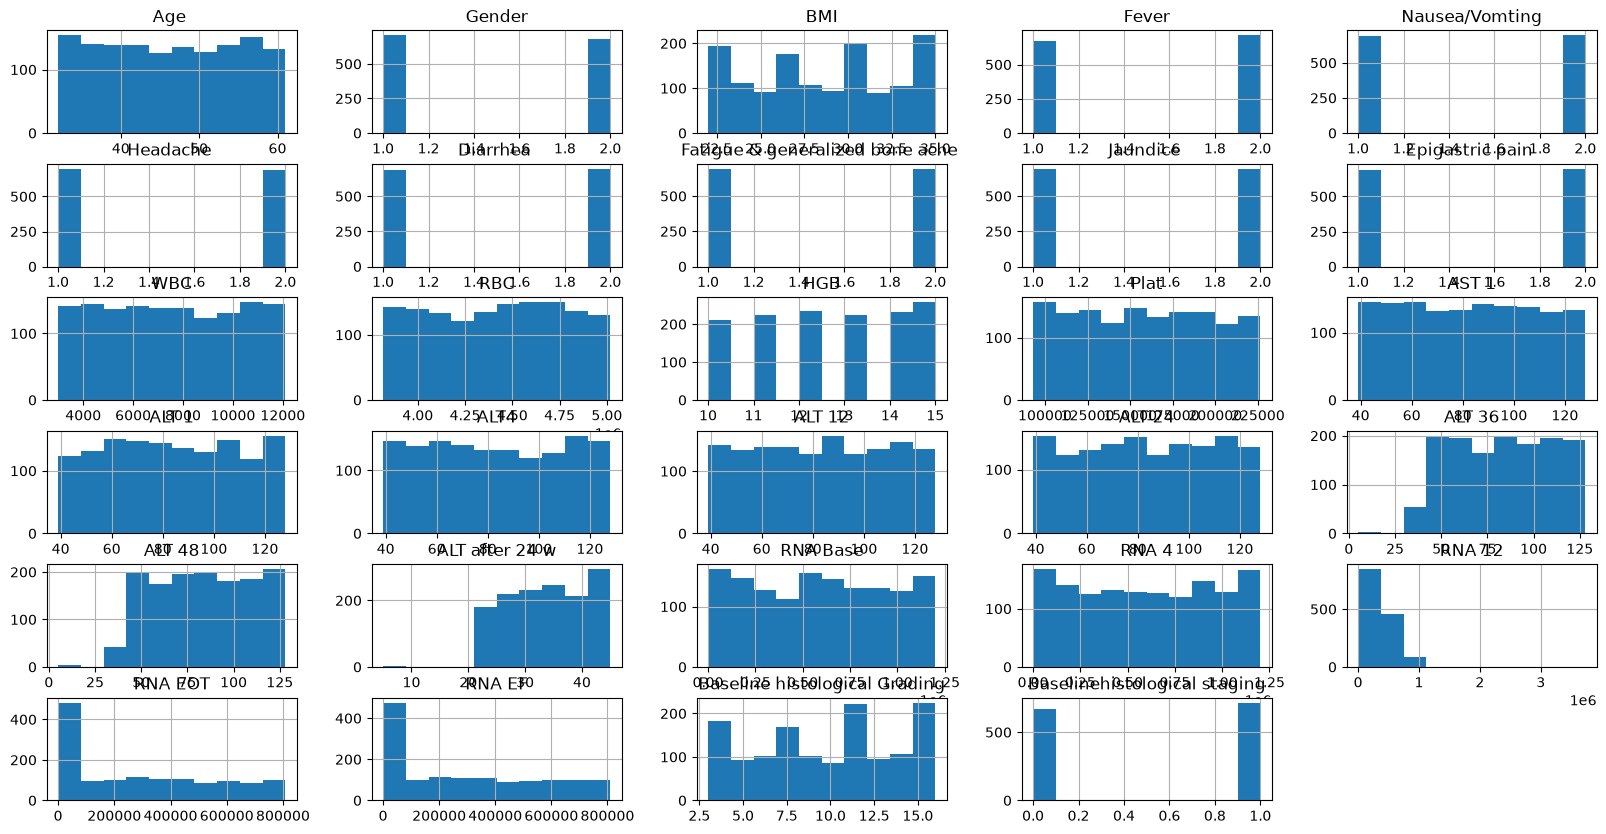

In [9]:
# Univariate Histograms
data_to_use.hist()
plt.show()

# We can see that perhaps the attributes Alkaline_Phosphotase has an exponential
# distribution. We can also see that perhaps the Age and Albumin and Albumin_and_Globulin_Ratio and
# Total_Protiens attributes may have a
# Gaussian or nearly Gaussian distribution. This is interesting because many machine learning
# techniques assume a Gaussian univariate distribution on the input variables.

**Density Plots**

Density plots are another way of getting a quick idea of the distribution of each attribute. The
plots look like an abstracted histogram with a smooth curve drawn through the top of each bin,
much like your eye tried to do with the histograms.

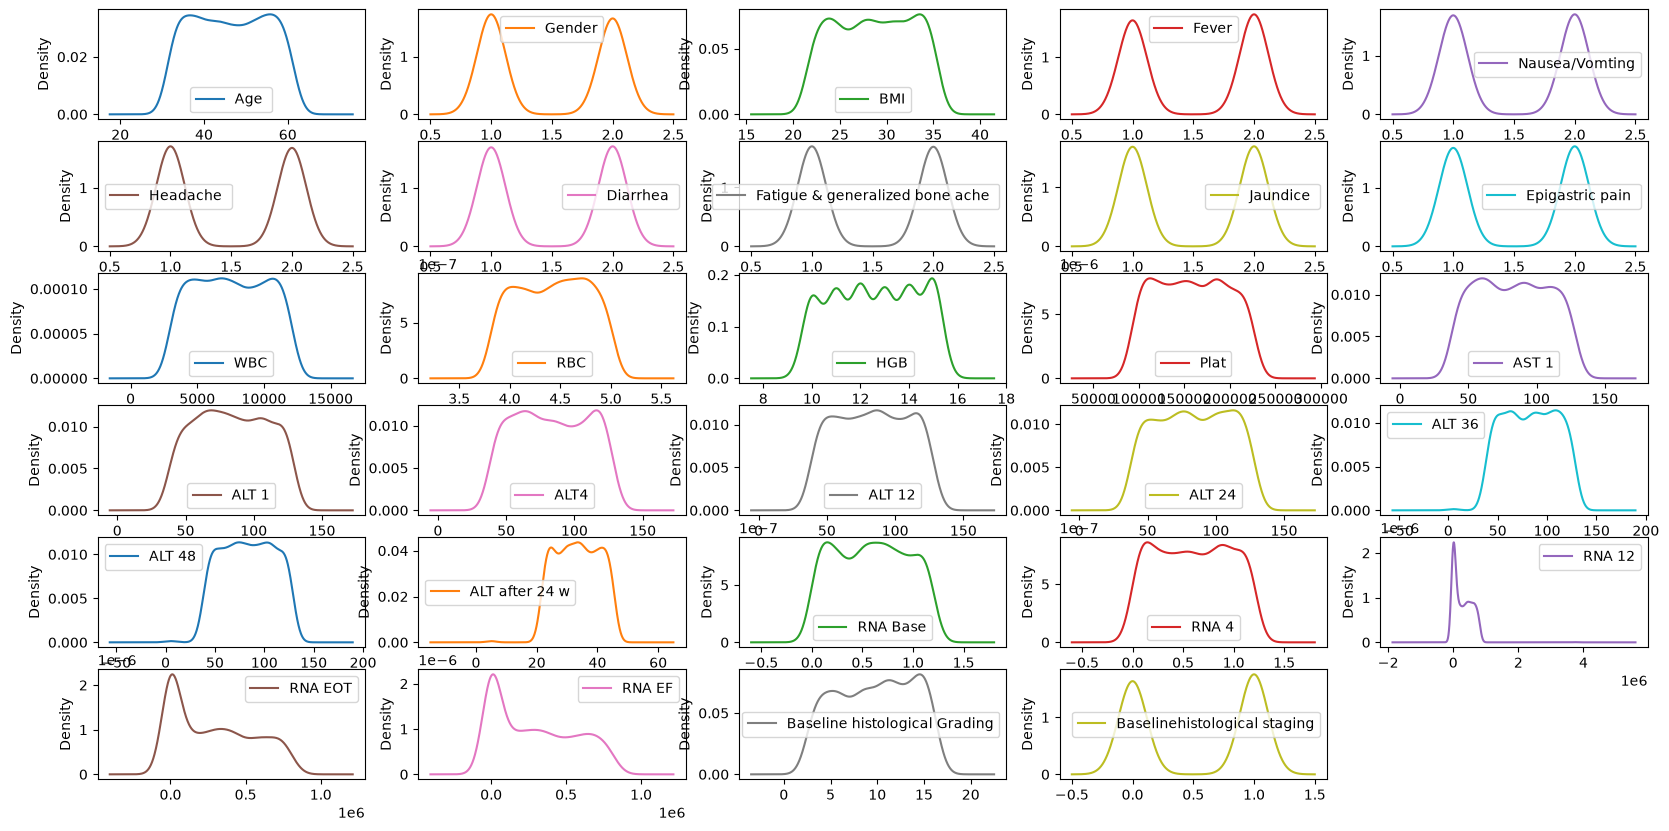

In [10]:
# Univariate Density Plots
data_to_use.plot(kind='density', subplots=True, layout=(6,5), sharex=False)
plt.show()

**Box and Whisker Plots**

Another useful way to review the distribution of each attribute is to use Box and Whisker Plots
or boxplots for short. Boxplots summarize the distribution of each attribute, drawing a line for
the median (middle value) and a box around the 25th and 75th percentiles (the middle 50% of
the data). The whiskers give an idea of the spread of the data and dots outside of the whiskers
show candidate outlier values (values that are 1.5 times greater than the size of spread of the
middle 50% of the data).

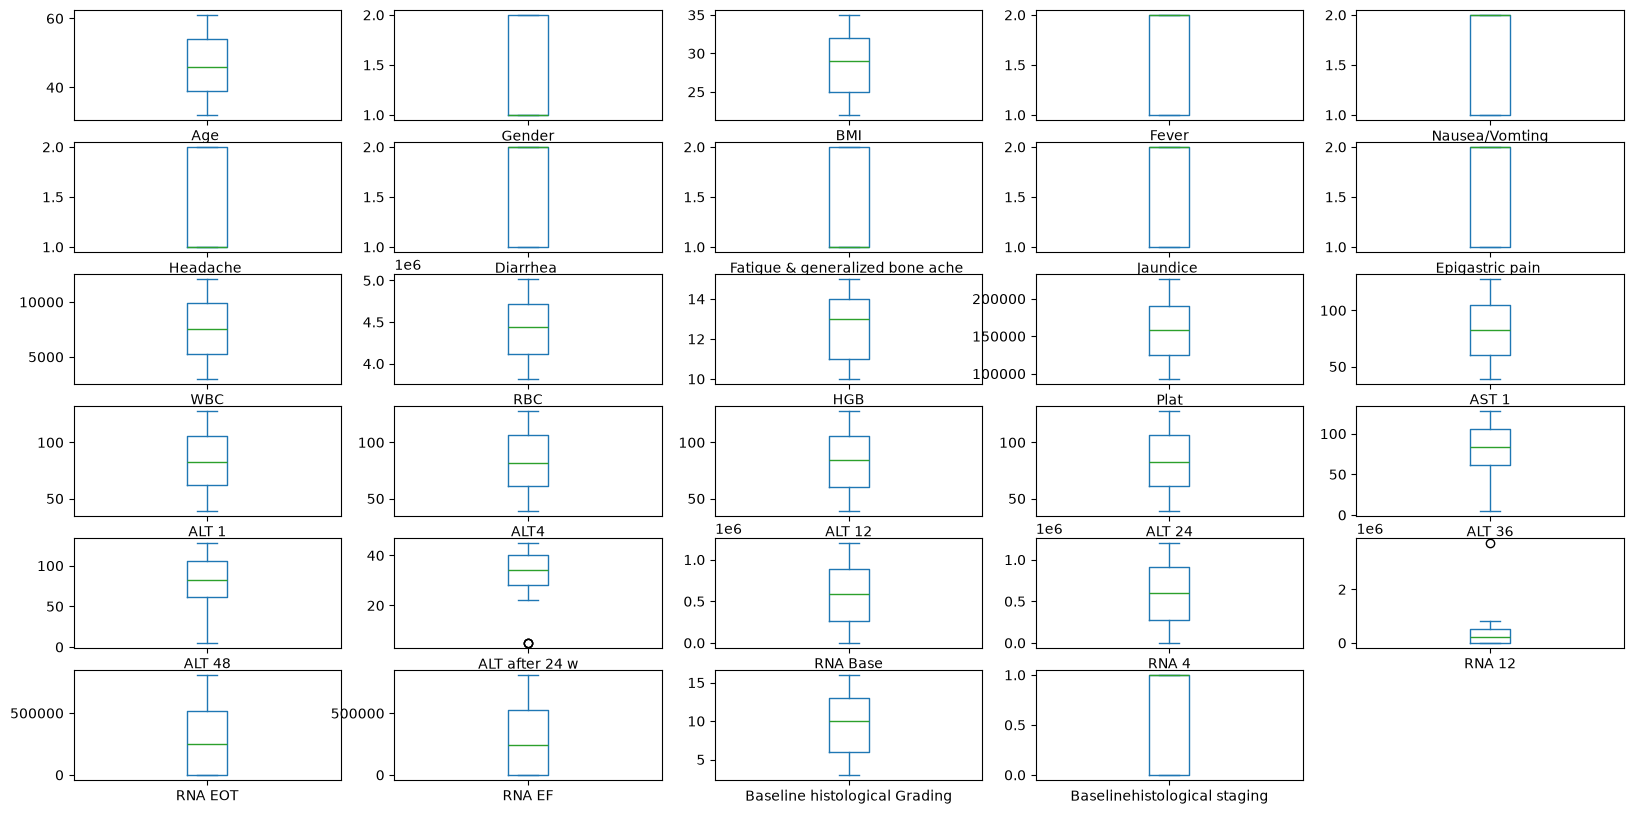

In [11]:
# Box and Whisker Plots
data.plot(kind='box', subplots=True, layout=(6,5), sharex=False, sharey=False)
plt.show()

# (2)Multivariate Plots

This section provides examples of two plots that show the interactions between multiple variables
in your dataset.

1.   Correlation Matrix Plot.
2.   Scatter Plot Matrix.

**Correlation Matrix Plot**

Correlation gives an indication of how related the changes are between two variables. If two
variables change in the same direction they are positively correlated. If they change in opposite
directions together (one goes up, one goes down), then they are negatively correlated. You can
calculate the correlation between each pair of attributes. This is called a correlation matrix. You
can then plot the correlation matrix and get an idea of which variables have a high correlation with each other. This is useful to know, because some machine learning algorithms like linear and logistic regression can have poor performance if there are highly correlated input variables in your data.

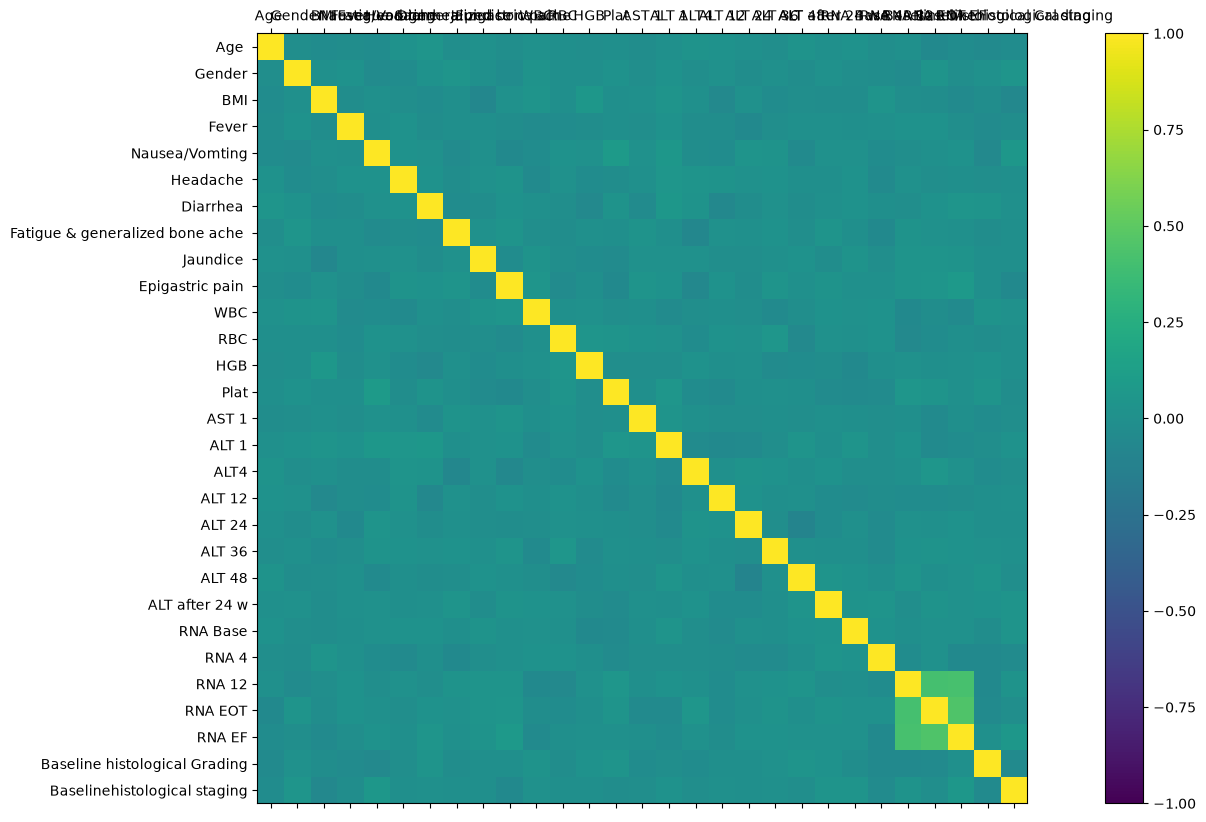

In [12]:
# Correction Matrix Plot

correlations = data_to_use.corr()
# plot correlation matrix
fig = plt.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(correlations, vmin=-1, vmax=1)
fig.colorbar(cax)
ticks = np.arange(0,len(data_to_use.columns),1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
names = list(data_to_use.columns)
ax.set_xticklabels(names)
ax.set_yticklabels(names)
plt.show()

**Scatter Plot Matrix**

A scatter plot shows the relationship between two variables as dots in two dimensions, one
axis for each attribute. You can create a scatter plot for each pair of attributes in your data.
Drawing all these scatter plots together is called a scatter plot matrix. Scatter plots are useful
for spotting structured relationships between variables, like whether you could summarize the
relationship between two variables with a line. Attributes with structured relationships may
also be correlated and good candidates for removal from your dataset.

Like the Correlation Matrix Plot above, the scatter plot matrix is symmetrical. This is
useful to look at the pairwise relationships from di
erent perspectives. Because there is little
point of drawing a scatter plot of each variable with itself, the diagonal shows histograms of
each attribute.

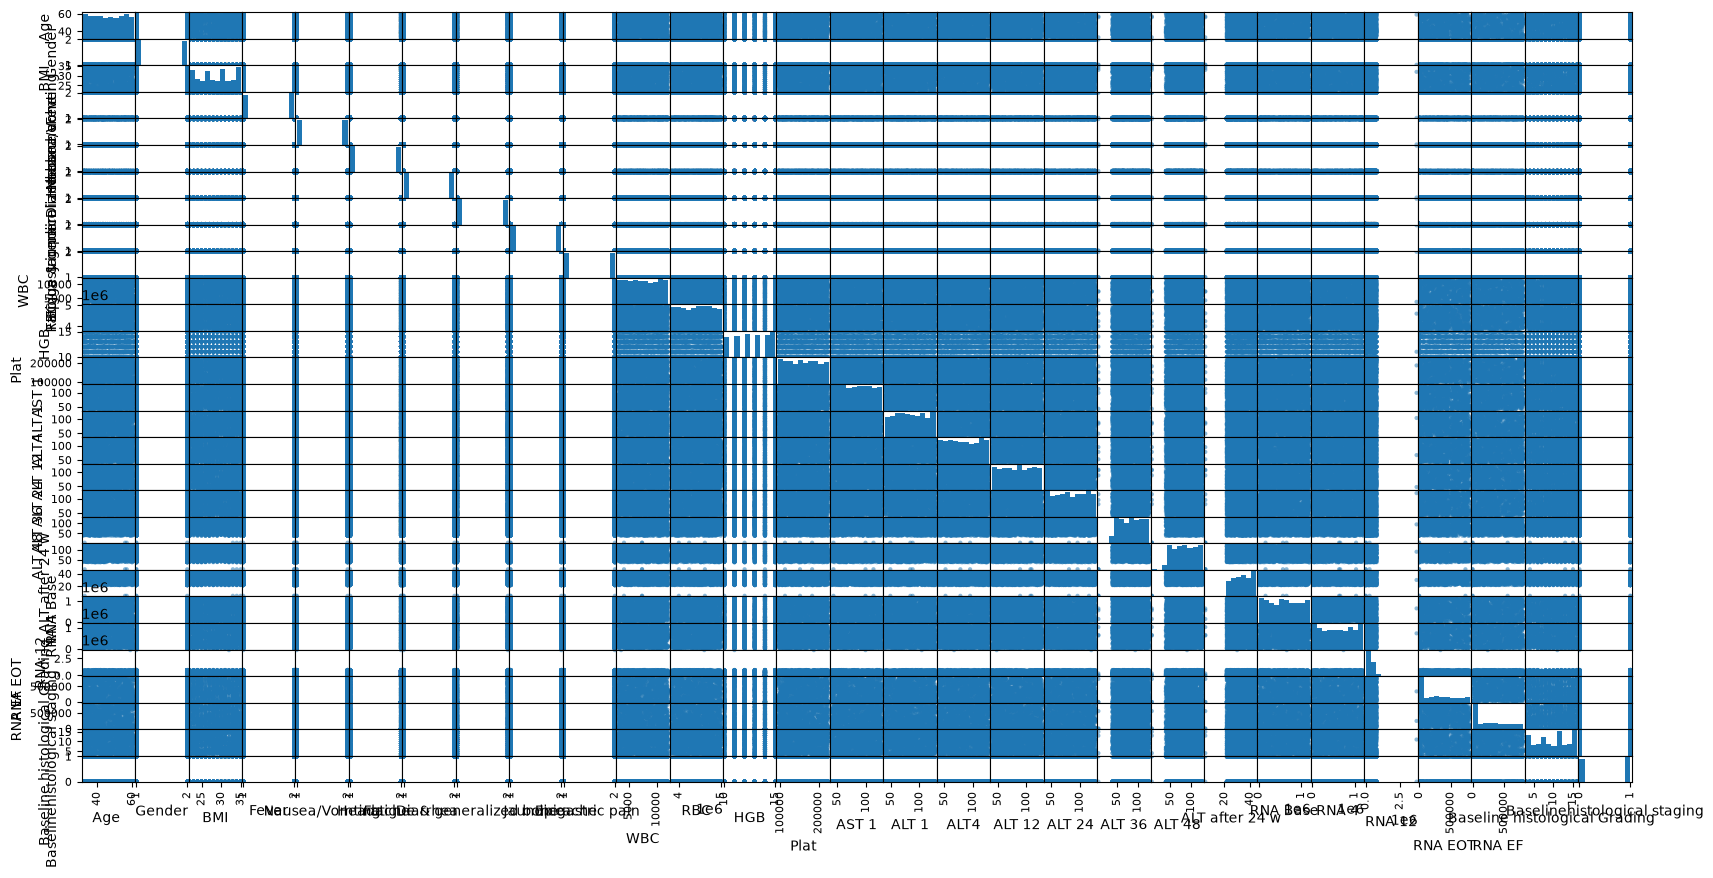

In [13]:
# Scatterplot Matrix

scatter_matrix(data_to_use)
plt.show()

# Prepare Your Data For Machine Learning

Many machine learning algorithms make assumptions about your data. It is often a very good
idea to prepare your data in such way to best expose the structure of the problem to the machine
learning algorithms that you intend to use. In this chapter you will discover how to prepare
your data for machine learning in Python using scikit-learn. After completing this lesson you
will know how to:
1. Rescale data.
2. Standardize data.
3. Normalize data.
4. Binarize data.

Let's get started.

**Need For Data Pre-processing**

You almost always need to pre-process your data. It is a required step. A diculty is that
di
erent algorithms make di
erent assumptions about your data and may require di
erent
transforms. Further, when you follow all of the rules and prepare your data, sometimes algorithms
can deliver better results without pre-processing.
Generally, I would recommend creating many di
erent views and transforms of your data,
then exercise a handful of algorithms on each view of your dataset. This will help you to 
ush
out which data transforms might be better at exposing the structure of your problem in general.

**Data Transforms**

In this lesson you will work through 4 di
erent data pre-processing recipes for machine learning.
The Pima Indian diabetes dataset is used in each recipe. Each recipe follows the same structure:
 
1.   Load the dataset from a URL.
2.   Split the dataset into the input and output variables for machine learning.
3. Apply a pre-processing transform to the input variables.
4. Summarize the data to show the change.

The scikit-learn library provides two standard idioms for transforming data. Each are useful
in di
erent circumstances. The transforms are calculated in such a way that they can be applied
to your training data and any samples of data you may have in the future. 
The scikit-learn documentation has some information on how to use various di
erent pre-processing methods:

1.    Fit and Multiple Transform.
2.   Combined Fit-And-Transform.

The Fit and Multiple Transform method is the preferred approach. You call the fit()
function to prepare the parameters of the transform once on your data. Then later you can use
the transform() function on the same data to prepare it for modeling and again on the test or
validation dataset or new data that you may see in the future. The Combined Fit-And-Transform
is a convenience that you can use for one o
 tasks. This might be useful if you are interested
in plotting or summarizing the transformed data.

# 1.Rescale Data
When your data is comprised of attributes with varying scales, many machine learning algorithms
can bene
t from rescaling the attributes to all have the same scale. Often this is referred to
as normalization and attributes are often rescaled into the range between 0 and 1. This is
useful for optimization algorithms used in the core of machine learning algorithms like gradient
descent. It is also useful for algorithms that weight inputs like regression and neural networks
and algorithms that use distance measures like k-Nearest Neighbors. You can rescale your data
using scikit-learn using the MinMaxScaler class

In [14]:
# Rescale data (between 0 and 1)
from sklearn.preprocessing import MinMaxScaler
from numpy import set_printoptions
# dataframe = read_csv(filename, names=names)
array = data_to_use.values
# print(array)

# separate array into input and output components
X = array[:,0:-1]
# print(X)
Y = array[:,-1]
# print(Y)

scaler = MinMaxScaler(feature_range=(0, 1))
rescaledX = scaler.fit_transform(X)
# summarize transformed data
pd.set_option('display.precision', 3)
set_printoptions(precision=3)
print(rescaledX[0:5,:])

[[0.828 0.    1.    1.    0.    0.    0.    1.    1.    1.    0.487 0.36
  0.8   0.143 0.674 0.506 0.146 0.787 0.472 0.    0.    0.    0.546 0.528
  0.077 0.    0.    0.769]
 [0.483 0.    0.538 0.    1.    1.    0.    1.    1.    0.    1.    0.51
  0.    0.272 0.584 0.944 0.629 0.404 0.831 0.423 0.959 0.975 0.034 0.448
  0.171 0.417 0.038 0.077]
 [0.862 0.    0.846 1.    1.    1.    1.    0.    0.    0.    0.13  0.67
  0.4   0.438 0.831 0.112 0.629 0.764 0.865 0.    0.    0.    0.476 0.55
  0.    0.91  0.69  0.077]
 [0.586 1.    0.846 0.    1.    0.    1.    0.    1.    0.    0.384 0.814
  0.    0.4   0.045 0.281 0.787 0.461 0.551 0.35  0.585 0.7   0.867 0.374
  0.157 0.921 0.719 0.538]
 [0.931 0.    0.769 0.    0.    1.    0.    1.    1.    1.    0.074 0.657
  0.2   0.709 0.674 0.73  0.315 0.101 0.91  0.724 0.691 0.625 0.55  0.615
  1.    0.419 0.3   0.615]]


# 2.Standardize Data

Standardization is a useful technique to transform attributes with a Gaussian distribution and
# di
ffering means and standard deviations to a standard Gaussian distribution with a mean of
0 and a standard deviation of 1. It is most suitable for techniques that assume a Gaussian
distribution in the input variables and work better with rescaled data, such as linear regression,
logistic regression and linear discriminate analysis. You can standardize data using scikit-learn
with the StandardScaler class

In [15]:
# Standardize data (0 mean, 1 stdev)
from sklearn.preprocessing import StandardScaler
from numpy import set_printoptions

array = data_to_use.values

# separate array into input and output components
X = array[:,0:-1]
# print(X)
Y = array[:,-1]
# print(Y)

scaler = StandardScaler().fit(X)
rescaledX = scaler.transform(X)
# summarize transformed data
set_printoptions(precision=3)
print(rescaledX[0:5,:])

[[ 1.103e+00 -9.793e-01  1.569e+00  9.694e-01 -1.005e+00 -9.921e-01
  -1.005e+00  1.002e+00  9.978e-01  9.921e-01 -4.064e-02 -5.006e-01
   8.245e-01 -1.192e+00  6.244e-01  3.232e-03 -1.184e+00  9.783e-01
  -1.034e-01 -2.960e+00 -2.999e+00 -4.022e+00  1.820e-01  9.288e-02
  -1.962e-03 -1.088e+00 -1.089e+00  8.050e-01]
 [-3.635e-02 -9.793e-01  9.604e-02 -1.032e+00  9.950e-01  1.008e+00
  -1.005e+00  1.002e+00  9.978e-01 -1.008e+00  1.712e+00  2.107e-02
  -1.511e+00 -7.473e-01  3.166e-01  1.508e+00  4.372e-01 -3.266e-01
   1.118e+00 -9.897e-01  1.502e+00  1.494e+00 -1.555e+00 -1.719e-01
   1.221e+00  1.858e-01 -9.727e-01 -1.432e+00]
 [ 1.217e+00 -9.793e-01  1.078e+00  9.694e-01  9.950e-01  1.008e+00
   9.950e-01 -9.978e-01 -1.002e+00 -1.008e+00 -1.258e+00  5.749e-01
  -3.431e-01 -1.760e-01  1.163e+00 -1.347e+00  4.372e-01  9.015e-01
   1.233e+00 -2.960e+00 -2.999e+00 -4.022e+00 -5.597e-02  1.669e-01
  -1.012e+00  1.695e+00  9.994e-01 -1.432e+00]
 [ 3.054e-01  1.021e+00  1.078e+00 -1.032e+

# 3.Normalize Data

Normalizing in scikit-learn refers to rescaling each observation (row) to have a length of 1 (called
a unit norm or a vector with the length of 1 in linear algebra). This pre-processing method
can be useful for sparse datasets (lots of zeros) with attributes of varying scales when using
algorithms that weight input values such as neural networks and algorithms that use distance
measures such as k-Nearest Neighbors. You can normalize data in Python with scikit-learn
using the Normalizer class

In [16]:
# Normalize data (length of 1)
from sklearn.preprocessing import Normalizer
from numpy import set_printoptions

array = data_to_use.values

# separate array into input and output components
X = array[:,0:-1]
Y = array[:,-1]
scaler = Normalizer().fit(X)
normalizedX = scaler.transform(X)
# summarize transformed data
set_printoptions(precision=3)
print(normalizedX[0:5,:])

[[1.285e-05 2.295e-07 8.034e-06 4.591e-07 2.295e-07 2.295e-07 2.295e-07
  4.591e-07 4.591e-07 4.591e-07 1.704e-03 9.753e-01 3.214e-06 2.574e-02
  2.272e-05 1.928e-05 1.194e-05 2.502e-05 1.859e-05 1.148e-06 1.148e-06
  1.148e-06 1.504e-01 1.456e-01 6.615e-02 1.148e-06 1.148e-06 2.984e-06]
 [1.017e-05 2.211e-07 6.413e-06 2.211e-07 4.423e-07 4.423e-07 2.211e-07
  4.423e-07 4.423e-07 2.211e-07 2.676e-03 9.795e-01 2.211e-06 2.861e-02
  2.012e-05 2.720e-05 2.101e-05 1.659e-05 2.499e-05 1.260e-05 2.720e-05
  9.730e-06 8.983e-03 1.191e-01 1.409e-01 7.448e-02 6.874e-03 8.846e-07]
 [1.189e-05 2.085e-07 6.882e-06 4.171e-07 4.171e-07 4.171e-07 4.171e-07
  2.085e-07 2.085e-07 2.085e-07 8.713e-04 9.637e-01 2.502e-06 3.160e-02
  2.356e-05 1.022e-05 1.981e-05 2.231e-05 2.419e-05 1.043e-06 1.043e-06
  1.043e-06 1.191e-01 1.379e-01 1.043e-06 1.535e-01 1.165e-01 8.341e-07]
 [9.697e-06 3.958e-07 6.531e-06 1.979e-07 3.958e-07 1.979e-07 3.958e-07
  1.979e-07 3.958e-07 1.979e-07 1.284e-03 9.488e-01 1.979e-06

# 4.Binarize Data (Make Binary)

You can transform your data using a binary threshold. All values above the threshold are
marked 1 and all equal to or below are marked as 0. This is called binarizing your data or
thresholding your data. It can be useful when you have probabilities that you want to make crisp
values. It is also useful when feature engineering and you want to add new features that indicate
something meaningful. You can create new binary attributes in Python using scikit-learn with
the Binarizer class

In [17]:
# binarization
from sklearn.preprocessing import Binarizer
from numpy import set_printoptions

array = data_to_use.values
print(array)
# separate array into input and output components
X = array[:,0:-1]
Y = array[:,-1]
binarizer = Binarizer(threshold=30.0).fit(X)
binaryX = binarizer.transform(X)
# summarize transformed data
set_printoptions(precision=3)
print(binaryX[0:5,:])

[[5.600e+01 1.000e+00 3.500e+01 ... 5.000e+00 1.300e+01 0.000e+00]
 [4.600e+01 1.000e+00 2.900e+01 ... 3.108e+04 4.000e+00 0.000e+00]
 [5.700e+01 1.000e+00 3.300e+01 ... 5.588e+05 4.000e+00 1.000e+00]
 ...
 [4.200e+01 1.000e+00 2.600e+01 ... 1.605e+05 6.000e+00 0.000e+00]
 [5.200e+01 1.000e+00 2.900e+01 ... 6.961e+05 1.500e+01 1.000e+00]
 [5.500e+01 2.000e+00 2.600e+01 ... 5.000e+00 1.300e+01 1.000e+00]]
[[1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 0. 0. 1. 1.
  1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
  1. 1. 1. 0.]
 [1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 0. 0. 1. 1.
  0. 1. 1. 0.]
 [1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
  1. 1. 1. 0.]
 [1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1.
  1. 1. 1. 0.]]


# Feature Selection For Machine Learning

The data features that you use to train your machine learning models have a huge influence on the performance you can achieve. Irrelevant or partially relevant features can negatively impact model performance. In this chapter you will discover automatic feature selection techniques
that you can use to prepare your machine learning data in Python with scikit-learn. After completing this lesson you will know how to use:
1. Univariate Selection.
2. Recursive Feature Elimination.
3. Principle Component Analysis.
4. Feature Importance.

# 1.Univariate Selection

Statistical tests can be used to select those features that have the strongest relationship with
the output variable. The scikit-learn library provides the SelectKBest class2 that can be used
with a suite of diff
erent statistical tests to select a specifi
c number of features. The example
below uses the chi-squared (chi2) statistical test for non-negative features to select 4 of the best
features from the dataset.

You can see the scores for each attribute and the 4 attributes chosen (those with the highest
scores): plas, test, mass and age. I got the names for the chosen attributes by manually
mapping the index of the 4 highest scores to the index of the attribute names.

In [18]:
# Feature Extraction with Univariate Statistical Tests (Chi-squared for classification)
from numpy import set_printoptions
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
array = data_to_use.values

X = array[:,0:-1]
Y = array[:,-1]
# feature extraction
test = SelectKBest(score_func=chi2, k=4)
fit = test.fit(X, Y)
# summarize scores
set_printoptions(precision=3)
print(fit.scores_)
features = fit.transform(X)
# summarize selected features
print(features[0:5,:])

[1.401e+00 3.809e-01 3.939e+00 8.388e-02 8.237e-01 8.235e-04 9.112e-04
 1.010e-03 1.473e-04 5.138e-01 9.229e+01 4.566e+02 3.662e-05 5.612e+03
 2.262e+00 5.851e+00 7.384e-01 2.385e-01 2.637e-01 8.913e-02 1.590e+00
 2.889e+00 3.753e+05 3.166e+05 3.462e+05 3.566e+04 1.043e+06 3.861e+00]
[[6.553e+05 6.345e+05 2.882e+05 5.000e+00]
 [4.062e+04 5.386e+05 6.371e+05 3.108e+04]
 [5.711e+05 6.613e+05 5.000e+00 5.588e+05]
 [1.042e+06 4.499e+05 5.857e+05 5.823e+05]
 [6.604e+05 7.388e+05 3.732e+06 2.429e+05]]


# 2.Recursive Feature Elimination

The Recursive Feature Elimination (or RFE) works by recursively removing attributes and
building a model on those attributes that remain. It uses the model accuracy to identify which
attributes (and combination of attributes) contribute the most to predicting the target attribute.
You can learn more about the RFE class3 in the scikit-learn documentation. The example below
uses RFE with the logistic regression algorithm to select the top 3 features. The choice of
algorithm does not matter too much as long as it is skillful and consistent.

You can see that RFE chose the top 3 features as preg, mass and pedi. These are marked
True in the support array and marked with a choice 1 in the ranking array. Again, you can
manually map the feature indexes to the indexes of attribute names.

In [19]:
# Feature Extraction with RFE
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
# feature extraction
model = LogisticRegression()
rfe = RFE(model, n_features_to_select=3)
fit = rfe.fit(X, Y)
# print("Num Features: %d") %fit.n_features_
print("Num Features:")
print(fit.n_features_)
# print("Selected Features: %s") % fit.support_
print("Selected Features:")
print(fit.support_)
# print("Feature Ranking: %s") % fit.ranking_
print("Feature Ranking:")
print(fit.ranking_)

Num Features:
3
Selected Features:
[False  True False False  True False False False False  True False False
 False False False False False False False False False False False False
 False False False False]
Feature Ranking:
[ 6  1  3  2  1 23 26 24 25  1 14 21 22 15 10  7 12  8 11  9 13  5 18 20
 19 17 16  4]


# 3.Principal Component Analysis

Principal Component Analysis (or PCA) uses linear algebra to transform the dataset into a
compressed form. Generally this is called a data reduction technique. A property of PCA is that
you can choose the number of dimensions or principal components in the transformed result. In
the example below, we use PCA and select 3 principal components.

In [20]:
# Feature Extraction with PCA
from sklearn.decomposition import PCA
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
# feature extraction
pca = PCA(n_components=3)
fit = pca.fit(X)
# summarize components
# print("Explained Variance: %s") % fit.explained_variance_ratio_
print("Explained Variance:")
print(fit.explained_variance_ratio_)

print(fit.components_)

Explained Variance:
[0.235 0.217 0.206]
[[-4.735e-07  4.856e-09 -4.358e-07  2.131e-08  1.665e-08  1.872e-08
   2.530e-08  6.176e-08  5.347e-08  8.325e-08 -3.948e-04 -2.537e-01
  -1.923e-08  4.690e-03 -1.157e-06 -9.234e-07  2.493e-06 -1.565e-06
   1.780e-06  1.892e-06  2.268e-06 -1.805e-07 -3.896e-02 -4.433e-01
   5.430e-01  4.520e-01  4.883e-01 -7.359e-08]
 [-3.293e-07 -3.626e-08  9.949e-08  7.669e-09 -2.505e-08 -3.235e-08
   2.332e-08 -4.450e-08  3.313e-08  4.842e-08  1.729e-05 -3.013e-02
  -1.230e-07 -3.470e-03 -1.418e-06 -2.199e-07  5.398e-09 -3.178e-06
  -1.424e-06 -1.291e-06  9.393e-07  8.684e-07  4.549e-01  7.849e-01
   2.503e-01  2.600e-01  2.142e-01 -7.184e-07]
 [ 7.354e-07 -1.030e-09 -3.207e-07 -1.313e-08  3.206e-08  5.678e-08
   1.721e-08  1.419e-08  3.036e-08 -2.014e-08  8.633e-05  1.564e-01
  -1.936e-07 -2.329e-03  6.624e-07  3.088e-06 -1.144e-06 -1.314e-06
   1.741e-06  9.918e-07  7.934e-07  2.511e-07  8.783e-01 -4.298e-01
  -9.917e-02 -8.311e-02 -5.165e-02  8.364e-08]]


# 4.Feature Importance

Bagged decision trees like Random Forest and Extra Trees can be used to estimate the importance
of features. In the example below we construct a ExtraTreesClassifier classi
er for dataset.

You can see that we are given an importance score for each attribute where the larger the
score, the more important the attribute. The scores suggest at the importance of plas, age
and mass.

In [21]:
# Feature Importance with Extra Trees Classifier
from sklearn.ensemble import ExtraTreesClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
# feature extraction
model = ExtraTreesClassifier()
model.fit(X, Y)
print(model.feature_importances_)

[0.041 0.022 0.04  0.026 0.018 0.027 0.026 0.025 0.026 0.022 0.042 0.04
 0.038 0.04  0.041 0.043 0.043 0.041 0.039 0.042 0.041 0.039 0.042 0.04
 0.038 0.037 0.04  0.041]


# Evaluate the Performance of Machine Learning Algorithms with Resampling

You need to know how well your algorithms perform on unseen data. The best way to evaluate
the performance of an algorithm would be to make predictions for new data to which you
already know the answers. The second best way is to use clever techniques from statistics called
resampling methods that allow you to make accurate estimates for how well your algorithm will
perform on new data. In this chapter you will discover how you can estimate the accuracy of
your machine learning algorithms using resampling methods in Python and scikit-learn on the dataset.


The evaluation is an estimate that we can use to talk about how well we think the algorithm
may actually do in practice. It is not a guarantee of performance. Once we estimate the
performance of our algorithm, we can then re-train the 
final algorithm on the entire training
dataset and get it ready for operational use. Next up we are going to look at four di
erent
techniques that we can use to split up our training dataset and create useful estimates of
performance for our machine learning algorithms:
 

1.   Train and Test Sets.
2.   k-fold Cross Validation.
3.   Leave One Out Cross Validation.
4.   Repeated Random Test-Train Splits.


 
 


# 1.Split into Train and Test Sets

The simplest method that we can use to evaluate the performance of a machine learning
algorithm is to use di
erent training and testing datasets. We can take our original dataset and
split it into two parts. Train the algorithm on the fi
rst part, make predictions on the second
part and evaluate the predictions against the expected results. The size of the split can depend
on the size and specifi
cs of your dataset, although it is common to use 67% of the data for
training and the remaining 33% for testing.
This algorithm evaluation technique is very fast. It is ideal for large datasets (millions of
records) where there is strong evidence that both splits of the data are representative of the
underlying problem. Because of the speed, it is useful to use this approach when the algorithm
you are investigating is slow to train. A downside of this technique is that it can have a high
variance. This means that di
fferences in the training and test dataset can result in meaningful
diff
erences in the estimate of accuracy. In the example below we split the dataset
into 67%/33% splits for training and test and evaluate the accuracy of a Logistic Regression
model.


We can see that the estimated accuracy for the model was approximately 75%. Note that
in addition to specifying the size of the split, we also specify the random seed. Because the
split of the data is random, we want to ensure that the results are reproducible. By specifying
the random seed we ensure that we get the same random numbers each time we run the code
and in turn the same split of data. This is important if we want to compare this result to
the estimated accuracy of another machine learning algorithm or the same algorithm with a
di
fferent con
figuration. To ensure the comparison was apples-for-apples, we must ensure that
they are trained and tested on exactly the same data.

In [22]:
# Evaluate using a train and a test set
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
test_size = 0.33
seed = 7
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size,
random_state=seed)
model = LogisticRegression()
model.fit(X_train, Y_train)
result = model.score(X_test, Y_test)
# print('Accuracy: %.3f%%') % (result*100.0)
print('Accuracy:')
print(result*100.0)

Accuracy:
54.14847161572053


# 2.K-fold Cross Validation

Cross validation is an approach that you can use to estimate the performance of a machine
learning algorithm with less variance than a single train-test set split. It works by splitting
the dataset into k-parts (e.g. k = 5 or k = 10). Each split of the data is called a fold. The
algorithm is trained on k - 1 folds with one held back and tested on the held back fold. This is
repeated so that each fold of the dataset is given a chance to be the held back test set. After
running cross validation you end up with k diff
erent performance scores that you can summarize
using a mean and a standard deviation.
The result is a more reliable estimate of the performance of the algorithm on new data. It is
more accurate because the algorithm is trained and evaluated multiple times on diff
erent data.
The choice of k must allow the size of each test partition to be large enough to be a reasonable
sample of the problem, whilst allowing enough repetitions of the train-test evaluation of the
algorithm to provide a fair estimate of the algorithms performance on unseen data. For modest
sized datasets in the thousands or tens of thousands of records, k values of 3, 5 and 10 are
common. In the example below we use 10-fold cross validation.

You can see that we report both the mean and the standard deviation of the performance
measure. When summarizing performance measures, it is a good practice to summarize the
distribution of the measures, in this case assuming a Gaussian distribution of performance (a
very reasonable assumption) and recording the mean and standard deviation.

In [23]:
# Evaluate using Cross Validation
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_folds = 10
seed = 7
kfold = KFold(n_splits=num_folds, shuffle=True, random_state=seed)
model = LogisticRegression()
results = cross_val_score(model, X, Y, cv=kfold)
# print("Accuracy: %.3f%% (%.3f%%)") % (results.mean()*100.0, results.std()*100.0)
print("Accuracy:")
print(results.mean()*100.0)
print(results.std()*100.0)

Accuracy:
51.47846939839433
5.234300619708228


# 3.Leave One Out Cross Validation

You can confi
gure cross validation so that the size of the fold is 1 (k is set to the number of
observations in your dataset). This variation of cross validation is called leave-one-out cross
validation. The result is a large number of performance measures that can be summarized in an eff
ort to give a more reasonable estimate of the accuracy of your model on unseen data.
A downside is that it can be a computationally more expensive procedure than k-fold cross
validation. In the example below we use leave-one-out cross validation.


You can see in the standard deviation that the score has more variance than the k-fold cross
validation results described above.

In [24]:
# Evaluate using Leave One Out Cross Validation
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_folds = 10
loocv = LeaveOneOut()
model = LogisticRegression(solver = 'lbfgs')
results = cross_val_score(model, X, Y, cv=loocv)
# print("Accuracy: /%.3f%% (%.3f%%)") % (results.mean()*100.0, results.std()*100.0)
print("Accuracy:")
print(results.mean()*100.0)
print(results.std()*100.0)

Accuracy:
51.26353790613718
49.98403216988156


# 4.Repeated Random Test-Train Splits


Another variation on k-fold cross validation is to create a random split of the data like the
train/test split described above, but repeat the process of splitting and evaluation of the
algorithm multiple times, like cross validation. This has the speed of using a train/test split and
the reduction in variance in the estimated performance of k-fold cross validation. You can also
repeat the process many more times as needed to improve the accuracy. A down side is that
repetitions may include much of the same data in the train or the test split from run to run,
introducing redundancy into the evaluation. The example below splits the data into a 67%/33%
train/test split and repeats the process 10 times.

In [25]:
# Evaluate using Shuffle Split Cross Validation
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
n_splits = 10
test_size = 0.33
seed = 7
kfold = ShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=seed)
model = LogisticRegression()
results = cross_val_score(model, X, Y, cv=kfold)
# print("Accuracy: %.3f%% (%.3f%%)") % (results.mean()*100.0, results.std()*100.0)
print("Accuracy:")
print(results.mean()*100.0)
print(results.std()*100.0)

Accuracy:
51.22270742358079
1.6576640083932157


# What Techniques to Use When
This section lists some tips to consider what resampling technique to use in di
fferent circum-stances.


*   Generally k-fold cross validation is the gold standard for evaluating the performance of a
machine learning algorithm on unseen data with k set to 3, 5, or 10.
*   Using a train/test split is good for speed when using a slow algorithm and produces
performance estimates with lower bias when using large datasets.
*   Techniques like leave-one-out cross validation and repeated random splits can be useful
intermediates when trying to balance variance in the estimated performance, model
training speed and dataset size.

The best advice is to experiment and 
find a technique for your problem that is fast and
produces reasonable estimates of performance that you can use to make decisions. If in doubt,
use 10-fold cross validation.

# Machine Learning Algorithm Performance Metrics

The metrics that you choose to evaluate your machine learning algorithms are very important.
Choice of metrics influences how the performance of machine learning algorithms is measured
and compared. They influence how you weight the importance of diff
erent characteristics in
the results and your ultimate choice of which algorithm to choose. In this chapter you will
discover how to select and use diff
erent machine learning performance metrics in Python with
scikit-learn. Let's get started.

**Algorithm Evaluation Metrics**

various diff
erent algorithm evaluation metrics are demonstrated for both classi
ffication and regression type machine learning problems.

All recipes evaluate the same algorithms, Logistic Regression for classi
cation and Linear
Regression for the regression problems. A 10-fold cross validation test harness is used to
demonstrate each metric, because this is the most likely scenario you will use when employing
di
fferent algorithm evaluation metrics.

**Classifi
cation Metrics**
Classi
cation problems are perhaps the most common type of machine learning problem and as
such there are a myriad of metrics that can be used to evaluate predictions for these problems.
In this section we will review how to use the following metrics:

*   Classifi
cation Accuracy.
*   Logarithmic Loss.
*   Area Under ROC Curve.
*   Confusion Matrix.
*   Classi
cation Report.


**Regression Metrics**
In this section will review 3 of the most common metrics for evaluating predictions on regression
machine learning problems:

*   Mean Absolute Error.
*   Mean Squared Error.
*   R2.

# 1.Classifi
cation Accuracy

Classifi
cation accuracy is the number of correct predictions made as a ratio of all predictions
made. This is the most common evaluation metric for classi
cation problems, it is also the most
misused. It is really only suitable when there are an equal number of observations in each class
(which is rarely the case) and that all predictions and prediction errors are equally important,
which is often not the case. Below is an example of calculating classifi
cation accuracy.

In [26]:
# Cross Validation Classification Accuracy
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LogisticRegression()
scoring = 'accuracy'
results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
# print("Accuracy: %.3f (%.3f)") % (results.mean(), results.std())
print("Accuracy:")
print(results.mean())
print(results.std())

# You can see that the ratio is reported. This can be converted into a percentage by multiplying
# the value by 100, giving an accuracy score of approximately 77% accurate.

Accuracy:
0.5147846939839433
0.05234300619708228


# 2.Logarithmic Loss

Logarithmic loss (or logloss) is a performance metric for evaluating the predictions of probabilities
of membership to a given class. The scalar probability between 0 and 1 can be seen as a measure
of con
fidence for a prediction by an algorithm. Predictions that are correct or incorrect are
rewarded or punished proportionally to the con
fidence of the prediction. Below is an example
of calculating logloss for Logistic regression predictions on the dataset.

In [27]:
# Cross Validation Classification LogLoss
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LogisticRegression()
scoring = 'neg_log_loss'
results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
# print("Logloss: %.3f (%.3f)") % (results.mean(), results.std())
print("Logloss:")
print(results.mean())
print(results.std())

# Smaller logloss is better with 0 representing a perfect logloss. As mentioned above, the
# measure is inverted to be ascending when using the cross val score() function.

Logloss:
-0.6938865813561668
0.006904768608021802


# 3.Area Under ROC Curve

Area under ROC Curve (or AUC for short) is a performance metric for binary classi
cation
problems. The AUC represents a model's ability to discriminate between positive and negative
classes. An area of 1.0 represents a model that made all predictions perfectly. An area of
0.5 represents a model that is as good as random. ROC can be broken down into sensitivity
and speci
city. A binary classi
cation problem is really a trade-o
ff between sensitivity and
speci
ficity.



*   Sensitivity is the true positive rate also called the recall. It is the number of instances
from the positive (
rst) class that actually predicted correctly

*   Speci
city is also called the true negative rate. Is the number of instances from the
negative (second) class that were actually predicted correctly.





In [28]:
# Cross Validation Classification ROC AUC
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LogisticRegression()
scoring = 'roc_auc'
results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
# print("AUC: %.3f (%.3f)") % (results.mean(), results.std())
print("AUC:")
print(results.mean())
print(results.std())


# You can see the AUC is relatively close to 1 and greater than 0.5, suggesting some skill in
# the predictions

AUC:
0.5268793069471519
0.038282705370484865


# 4.Confusion Matrix

The confusion matrix is a handy presentation of the accuracy of a model with two or more
classes. The table presents predictions on the x-axis and accuracy outcomes on the y-axis. The
cells of the table are the number of predictions made by a machine learning algorithm. For
example, a machine learning algorithm can predict 0 or 1 and each prediction may actually have
been a 0 or 1. Predictions for 0 that were actually 0 appear in the cell for prediction = 0 and
actual = 0, whereas predictions for 0 that were actually 1 appear in the cell for prediction = 0
and actual = 1. And so on. Below is an example of calculating a confusion matrix for a set of
predictions by a Logistic Regression on the Pima Indians onset of diabetes dataset.

In [29]:
# Cross Validation Classification Confusion Matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
test_size = 0.33
seed = 7
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size,
random_state=seed)
model = LogisticRegression()
model.fit(X_train, Y_train)
predicted = model.predict(X_test)
matrix = confusion_matrix(Y_test, predicted)
print(matrix)

# Although the array is printed without headings, you can see that the majority of the
# predictions fall on the diagonal line of the matrix (which are correct predictions).

[[ 71 149]
 [ 61 177]]


# 5.Classi
cation Report

The scikit-learn library provides a convenience report when working on classi
cation prob-lems to give you a quick idea of the accuracy of a model using a number of measures. The
classification report() function displays the precision, recall, F1-score and support for each
class. The example below demonstrates the report on the binary classi
cation problem.

In [30]:
# Cross Validation Classification Report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
test_size = 0.33
seed = 7
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size,
random_state=seed)
model = LogisticRegression()
model.fit(X_train, Y_train)
predicted = model.predict(X_test)
report = classification_report(Y_test, predicted)
print(report)

              precision    recall  f1-score   support

         0.0       0.54      0.32      0.40       220
         1.0       0.54      0.74      0.63       238

    accuracy                           0.54       458
   macro avg       0.54      0.53      0.52       458
weighted avg       0.54      0.54      0.52       458



#**Regression Metrics**
In this section will review 3 of the most common metrics for evaluating predictions on regression
machine learning problems:

*   Mean Absolute Error.
*   Mean Squared Error.
*   R2.

# 1.Mean Absolute Error

The Mean Absolute Error (or MAE) is the sum of the absolute diff
erences between predictions
and actual values. It gives an idea of how wrong the predictions were. The measure gives an
idea of the magnitude of the error, but no idea of the direction (e.g. over or under predicting).
The example below demonstrates calculating mean absolute error on the Boston house price
dataset.

In [31]:
# Cross Validation Regression MAE
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LinearRegression()
scoring = 'neg_mean_absolute_error'
results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
# print("MAE: %.3f (%.3f)") % (results.mean(), results.std())
print("MAE:")
print(results.mean())
print(results.std())

# A value of 0 indicates no error or perfect predictions. Like logloss, this metric is inverted by
# the cross val score() function.

MAE:
-0.4966644851522789
0.005779316091328001


# 2.Mean Squared Error

The Mean Squared Error (or MSE) is much like the mean absolute error in that it provides a
gross idea of the magnitude of error. Taking the square root of the mean squared error converts
the units back to the original units of the output variable and can be meaningful for description
and presentation. This is called the Root Mean Squared Error (or RMSE). The example below
provides a demonstration of calculating mean squared error.

In [32]:
# Cross Validation Regression MSE
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_folds = 10
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LinearRegression()
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
# print("MSE: %.3f (%.3f)") % (results.mean(), results.std())
print("MSE:")
print(results.mean())
print(results.std())

# This metric too is inverted so that the results are increasing. Remember to take the absolute
# value before taking the square root if you are interested in calculating the RMSE.

MSE:
-0.25407426130153005
0.005776672203093906


# 3.R2 Metric

The R2 (or R Squared) metric provides an indication of the goodness of 
fit of a set of predictions
to the actual values. In statistical literature this measure is called the coecient of determination.
This is a value between 0 and 1 for no-
fit and perfect 
fit respectively. The example below
provides a demonstration of calculating the mean R2 for a set of predictions.

In [33]:
# Cross Validation Regression R^2
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LinearRegression()
scoring = 'r2'
results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
# print("R^2: %.3f (%.3f)") % (results.mean(), results.std())
print("R^2:")
print(results.mean())
print(results.std())

# values = data_to_use.values

# Y = values[:,9]
# X = values[:,0:9]

R^2:
-0.024618298550030792
0.02134438419744045


**Summary**

In this chapter you discovered metrics that you can use to evaluate your machine learning
algorithms.
You learned about three classifi
cation metrics: Accuracy, Logarithmic Loss and Area Under
ROC Curve. You also learned about two convenience methods for classi
fication prediction
results: the Confusion Matrix and the Classifi
cation Report. Finally, you also learned about
three metrics for regression problems: Mean Absolute Error, Mean Squared Error and R2.

You now know how to evaluate the performance of machine learning algorithms using a variety
of di
erent metrics and how to use those metrics to estimate the performance of algorithms on
new unseen data using resampling. In the next lesson you will start looking at machine learning
algorithms themselves, starting with classi
cation techniques.

# Spot-Check Classi
cation Algorithms

Spot-checking is a way of discovering which algorithms 


perform well on your machine learning
problem. You cannot know which algorithms are best suited to your problem beforehand. You
must trial a number of methods and focus attention on those that prove themselves the most
promising. In this chapter you will discover six machine learning algorithms that you can use
when spot-checking your classi
cation problem in Python with scikit-learn. After completing
this lesson you will know:
1. How to spot-check machine learning algorithms on a classi
cation problem.
2. How to spot-check two linear classi
cation algorithms.
3. How to spot-check four nonlinear classi
cation algorithms.

We are going to take a look at six classi
cation algorithms that you can spot-check on your
dataset. Starting with two linear machine learning algorithms:

1.   Logistic Regression.
2.   Linear Discriminant Analysis.

Then looking at four nonlinear machine learning algorithms:

*   k-Nearest Neighbors.
*   Naive Bayes.
*   Classi
cation and Regression Trees.
*   Support Vector Machines.

# Linear Machine Learning Algorithms

This section demonstrates minimal recipes for how to use two linear machine learning algorithms:
logistic regression and linear discriminant analysis.

# 1.Logistic Regression

Logistic regression assumes a Gaussian distribution for the numeric input variables and can
model binary classifi
cation problems. You can construct a logistic regression model using the
LogisticRegression class1.

In [34]:
# Logistic Regression Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_folds = 10
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LogisticRegression()
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean()) #Running the example prints the mean estimated accuracy.

0.5147846939839433


# 2.Linear Discriminant Analysis

Linear Discriminant Analysis or LDA is a statistical technique for binary and multiclass
classi
fication. It too assumes a Gaussian distribution for the numerical input variables. You can
construct an LDA model using the LinearDiscriminantAnalysis class

In [35]:
# LDA Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_folds = 10
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = LinearDiscriminantAnalysis()
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())#Running the example prints the mean estimated accuracy.

0.5104994265457199


# Nonlinear Machine Learning Algorithms

This section demonstrates minimal recipes for how to use 4 nonlinear machine learning algorithms.

# 1.k-Nearest Neighbors

The k-Nearest Neighbors algorithm (or KNN) uses a distance metric to 
nd the k most similar
instances in the training data for a new instance and takes the mean outcome of the neighbors
as the prediction. You can construct a KNN model using the KNeighborsClassifier class

In [36]:
# KNN Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_folds = 10
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = KNeighborsClassifier()
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())#Running the example prints the mean estimated accuracy.

0.47654050672505477


# 2.Naive Bayes

Naive Bayes calculates the probability of each class and the conditional probability of each class
given each input value. These probabilities are estimated for new data and multiplied together,
assuming that they are all independent (a simple or naive assumption). When working with
real-valued data, a Gaussian distribution is assumed to easily estimate the probabilities for
input variables using the Gaussian Probability Density Function. You can construct a Naive
Bayes model using the GaussianNB class

In [37]:
# Gaussian Naive Bayes Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = GaussianNB()
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())#Running the example prints the mean estimated accuracy.

0.48879157543530394


# 3.Classi
cation and Regression Trees

Classi
cation and Regression Trees (CART or just decision trees) construct a binary tree from
the training data. Split points are chosen greedily by evaluating each attribute and each value
of each attribute in the training data in order to minimize a cost function (like the Gini index).
You can construct a CART model using the DecisionTreeClassifier class

In [38]:
# CART Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = DecisionTreeClassifier()
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())#Running the example prints the mean estimated accuracy.

0.50475967052445


# 4.Support Vector Machines

Support Vector Machines (or SVM) seek a line that best separates two classes. Those data
instances that are closest to the line that best separates the classes are called support vectors
and influence where the line is placed. SVM has been extended to support multiple classes.
Of particular importance is the use of di
erent kernel functions via the kernel parameter. A powerful Radial Basis Function is used by default. You can construct an SVM model using the SVC class

In [39]:
# SVM Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = SVC()
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())#Running the example prints the mean estimated accuracy.

0.5162287561255343


**Summary**
In this chapter you discovered 6 machine learning algorithms that you can use to spot-check
on your classi
cation problem in Python using scikit-learn. Speci
cally, you learned how to
spot-check two linear machine learning algorithms: Logistic Regression and Linear Discriminant
Analysis. You also learned how to spot-check four nonlinear algorithms: k-Nearest Neighbors,
Naive Bayes, Classi
cation and Regression Trees and Support Vector Machines.

# Spot-Check Regression Algorithms

In this lesson we are going to take a look at seven regression algorithms that you can spot-check
on your dataset. Starting with four linear machine learning algorithms:
1.   Linear Regression.
2.   Ridge Regression.
3.   LASSO Linear Regression.
4.   Elastic Net Regression.


Then looking at three nonlinear machine learning algorithms:
1.   k-Nearest Neighbors.
2.   Classi
cation and Regression Trees.
3.   Support Vector Machines.

# A.Improve Performance with Ensembles

Ensembles can give you a boost in accuracy on your dataset. In this chapter you will discover
how you can create some of the most powerful types of ensembles in Python using scikit-learn.
This lesson will step you through Boosting, Bagging and Majority Voting and show you how you
can continue to ratchet up the accuracy of the models on your own datasets. After completing
this lesson you will know:
1. How to use bagging ensemble methods such as bagged decision trees, random forest and
extra trees.
2. How to use boosting ensemble methods such as AdaBoost and stochastic gradient boosting.
3. How to use voting ensemble methods to combine the predictions from multiple algorithms.
Let's get started.


**Combine Models Into Ensemble Predictions**

The three most popular methods for combining the predictions from di
erent models are:

 **1-Bagging**. Building multiple models (typically of the same type) from di
erent subsamples of the training dataset.
 

 **2-Boosting**. Building multiple models (typically of the same type) each of which learns to 
x the prediction errors of a prior model in the sequence of models.

 **3-Voting**. Building multiple models (typically of di
ering types) and simple statistics (like calculating the mean) are used to combine predictions.
Each ensemble algorithm is demonstrated using 10-fold cross validation and the classi
cation accuracy performance metric.

# A.1Bagging Algorithms

Bootstrap Aggregation (or Bagging) involves taking multiple samples from your training dataset
(with replacement) and training a model for each sample. The 
nal output prediction is averaged
across the predictions of all of the sub-models. The three bagging models covered in this section
are as follows:

1.   Bagged Decision Trees.
2.   Random Forest.
3.   Extra Trees.

# A.1.1 Bagged Decision Trees

Bagging performs best with algorithms that have high variance. A popular example are
decision trees, often constructed without pruning. In the example below is an example
of using the BaggingClassifier with the Classi
cation and Regression Trees algorithm
(DecisionTreeClassifier1). A total of 100 trees are created.

In [40]:
# Bagged Decision Trees for Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
seed = 7
kfold = KFold(n_splits=10, shuffle=True, random_state=seed)
cart = DecisionTreeClassifier()
num_trees = 100
model = BaggingClassifier(estimator=cart, n_estimators=num_trees, random_state=seed)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())#Running the example, we get a robust estimate of model accuracy.

0.49459910332603474


# A.1.2Random Forest

Random Forests is an extension of bagged decision trees. Samples of the training dataset are
taken with replacement, but the trees are constructed in a way that reduces the correlation
between individual classi
ers. Speci
cally, rather than greedily choosing the best split point in
the construction of each tree, only a random subset of features are considered for each split. You
can construct a Random Forest model for classi
cation using the RandomForestClassifier
class2. The example below demonstrates using Random Forest for classi
cation with 100 trees
and split points chosen from a random selection of 3 features.

In [42]:
# Random Forest Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_trees = 100
max_features = 3
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = RandomForestClassifier(n_estimators=num_trees, max_features=max_features)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean()) #Running the example provides a mean estimate of classification accuracy.

0.4982170785111041


# A.1.3Extra Trees

Extra Trees are another modi
cation of bagging where random trees are constructed from
samples of the training dataset. You can construct an Extra Trees model for classi
cation using
the ExtraTreesClassifier class3. The example below provides a demonstration of extra trees
with the number of trees set to 100 and splits chosen from 7 random features.

In [43]:
# Extra Trees Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import ExtraTreesClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_trees = 100
max_features = 7
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
model = ExtraTreesClassifier(n_estimators=num_trees, max_features=max_features)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())

0.4808831195912835


# A.2 Boosting Algorithms

Boosting ensemble algorithms creates a sequence of models that attempt to correct the mistakes
of the models before them in the sequence. Once created, the models make predictions which
may be weighted by their demonstrated accuracy and the results are combined to create a 
nal
output prediction. The two most common boosting ensemble machine learning algorithms are:

 1.AdaBoost.

 2.Stochastic Gradient Boosting.

# A.2.1AdaBoost

AdaBoost was perhaps the 
rst successful boosting ensemble algorithm. It generally works
by weighting instances in the dataset by how easy or dicult they are to classify, allowing
the algorithm to pay or less attention to them in the construction of subsequent models. You
can construct an AdaBoost model for classi
cation using the AdaBoostClassifier class4. The
example below demonstrates the construction of 30 decision trees in sequence using the AdaBoost
algorithm.

In [44]:
# AdaBoost Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import AdaBoostClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
num_trees = 30
seed=7
kfold = KFold(n_splits=10, shuffle=True, random_state=seed)
model = AdaBoostClassifier(n_estimators=num_trees, random_state=seed)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean()) #Running the example provides a mean estimate of classification accuracy.

0.4837608174330101


# A.2.2Stochastic Gradient Boosting

Stochastic Gradient Boosting (also called Gradient Boosting Machines) are one of the most
sophisticated ensemble techniques. It is also a technique that is proving to be perhaps one of
the best techniques available for improving performance via ensembles. You can construct a
Gradient Boosting model for classi
cation using the GradientBoostingClassifier class5. The
example below demonstrates Stochastic Gradient Boosting for classi
cation with 100 trees.

In [45]:
# Stochastic Gradient Boosting Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
seed = 7
num_trees = 100
kfold = KFold(n_splits=10, shuffle=True, random_state=seed)
model = GradientBoostingClassifier(n_estimators=num_trees, random_state=seed)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean()) #Running the example provides a mean estimate of classification accuracy.

0.4974611615055782


# A.3Voting Ensemble

Voting is one of the simplest ways of combining the predictions from multiple machine learning
algorithms. It works by 
rst creating two or more standalone models from your training dataset.
A Voting Classi
er can then be used to wrap your models and average the predictions of the
sub-models when asked to make predictions for new data. The predictions of the sub-models can
be weighted, but specifying the weights for classi
ers manually or even heuristically is dicult.
More advanced methods can learn how to best weight the predictions from sub-models, but this
is called stacking (stacked aggregation) and is currently not provided in scikit-learn.
You can create a voting ensemble model for classi
cation using the VotingClassifier
class6. The code below provides an example of combining the predictions of logistic regression,
classi
cation and regression trees and support vector machines together for a classi
cation
problem.

In [46]:
# Voting Ensemble for Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
kfold = KFold(n_splits=10, shuffle=True, random_state=7)
# create the sub models
estimators = []
model1 = LogisticRegression()
estimators.append(('logistic', model1))
model2 = DecisionTreeClassifier()
estimators.append(('cart', model2))
model3 = SVC()
estimators.append(('svm', model3))
# create the ensemble model
ensemble = VotingClassifier(estimators)
results = cross_val_score(ensemble, X, Y, cv=kfold)
print(results.mean()) #Running the example provides a mean estimate of classification accuracy.

0.5234490668334898


Summary
In this chapter you discovered ensemble machine learning algorithms for improving the perfor-
mance of models on your problems. You learned about:

 Bagging Ensembles including Bagged Decision Trees, Random Forest and Extra Trees.

 Boosting Ensembles including AdaBoost and Stochastic Gradient Boosting.

 Voting Ensembles for averaging the predictions for any arbitrary models.

# B.Improve Performance with Algorithm Tuning

Machine learning models are parameterized so that their behavior can be tuned for a given
problem. Models can have many parameters and 
nding the best combination of parameters can
be treated as a search problem. In this chapter you will discover how to tune the parameters of
machine learning algorithms in Python using the scikit-learn. After completing this lesson you
will know:
1. The importance of algorithm parameter tuning to improve algorithm performance.
2. How to use a grid search algorithm tuning strategy.
3. How to use a random search algorithm tuning strategy.
Let's get started.

**Machine Learning Algorithm Parameters**
Algorithm tuning is a 
nal step in the process of applied machine learning before 
nalizing your
model. It is sometimes called hyperparameter optimization where the algorithm parameters
are referred to as hyperparameters, whereas the coecients found by the machine learning
algorithm itself are referred to as parameters. Optimization suggests the search-nature of the
problem. Phrased as a search problem, you can use di
erent search strategies to 
nd a good and
robust parameter or set of parameters for an algorithm on a given problem. Python scikit-learn
provides two simple methods for algorithm parameter tuning:
*   Grid Search Parameter Tuning.
*   Random Search Parameter Tuning.

# B1.Grid Search Parameter Tuning

Grid search is an approach to parameter tuning that will methodically build and evaluate a
model for each combination of algorithm parameters speci
fied in a grid. You can perform a grid
search using the GridSearchCV class1. The example below evaluates di
fferent alpha values for
the Ridge Regression algorithm on the standard diabetes dataset. This is a one-dimensional
grid search.

In [48]:
# Grid Search for Algorithm Tuning
import numpy
from pandas import read_csv
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
alphas = numpy.array([1,0.1,0.01,0.001,0.0001,0])
param_grid = dict(alpha=alphas)
model = Ridge()
grid = GridSearchCV(estimator=model, param_grid=param_grid)
grid.fit(X, Y)
print(grid.best_score_)
print(grid.best_estimator_.alpha)
#Running the example lists out the optimal score achieved and the set of parameters in the
# grid that achieved that score. In this case the alpha value of 1.0.

-0.019674847049843347
1.0


# B2.Random Search Parameter Tuning

Random search is an approach to parameter tuning that will sample algorithm parameters from
a random distribution (i.e. uniform) for a 
xed number of iterations. A model is constructed
and evaluated for each combination of parameters chosen. You can perform a random search
for algorithm parameters using the RandomizedSearchCV class2. The example below evaluates
di
erent random alpha values between 0 and 1 for the Ridge Regression algorithm on the
standard diabetes dataset. A total of 100 iterations are performed with uniformly random alpha
values selected in the range between 0 and 1 (the range that alpha values can take).

In [49]:
# Randomized for Algorithm Tuning
import numpy
from scipy.stats import uniform
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
param_grid = {'alpha': uniform()}
model = Ridge()
rsearch = RandomizedSearchCV(estimator=model, param_distributions=param_grid, n_iter=100,
random_state=7)
rsearch.fit(X, Y)
print(rsearch.best_score_)
print(rsearch.best_estimator_.alpha)
# Running the example produces results much like those in the grid search example above. An
# optimal alpha value near 1.0 is discovered.

-0.019675761911201996
0.9779895119966027


**Summary**
Algorithm parameter tuning is an important step for improving algorithm performance right
before presenting results or preparing a system for production. In this chapter you discovered
algorithm parameter tuning and two methods that you can use right now in Python and
scikit-learn to improve your algorithm results:

 Grid Search Parameter Tuning

 Random Search Parameter Tuning

**Next**
This lesson concludes the coverage of techniques that you can use to improve the performance of
algorithms on your dataset. In the next and 
nal lesson you will discover how you can 
nalize
your model for using it on unseen data.

# Save and Load Machine Learning Models

Finding an accurate machine learning model is not the end of the project. In this chapter you
will discover how to save and load your machine learning model in Python using scikit-learn.
This allows you to save your model to 
le and load it later in order to make predictions. After
completing this lesson you will know:
1. The importance of serializing models for reuse.
2. How to use pickle to serialize and deserialize machine learning models.
3. How to use Joblib to serialize and deserialize machine learning models.
Let's get started.

# 1.Finalize Your Model with pickle

Pickle is the standard way of serializing objects in Python. You can use the pickle1 operation
to serialize your machine learning algorithms and save the serialized format to a 
le. Later you
can load this 
le to deserialize your model and use it to make new predictions. The example
below demonstrates how you can train a logistic regression model on the Pima Indians onset of
diabetes dataset, save the model to 
le and load it to make predictions on the unseen test set.

In [50]:
# Save Model Using Pickle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from pickle import dump
from pickle import load
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.33, random_state=7)
# Fit the model on 33%
model = LogisticRegression()
model.fit(X_train, Y_train)
# save the model to disk
filename = 'finalized_model.sav'
dump(model, open(filename, 'wb'))

# some time later...

# load the model from disk
loaded_model = load(open(filename, 'rb'))
result = loaded_model.score(X_test, Y_test)
print(result)

# Running the example saves the model to finalized model.sav in your local working
# directory. Load the saved model and evaluating it provides an estimate of accuracy of the model
# on unseen data.

0.5414847161572053


# 2.Finalize Your Model with Joblib

The Joblib2 library is part of the SciPy ecosystem and provides utilities for pipelining Python
jobs. It provides utilities for saving and loading Python objects that make use of NumPy data
structures, eciently3. This can be useful for some machine learning algorithms that require a
lot of parameters or store the entire dataset (e.g. k-Nearest Neighbors). The example below
demonstrates how you can train a logistic regression model on the Pima Indians onset of diabetes
dataset, save the model to 
le using Joblib and load it to make predictions on the unseen test
set.

In [52]:
# Save Model Using joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from joblib import dump
from joblib import load
array = data_to_use.values
X = array[:,0:-1]
Y = array[:,-1]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.33, random_state=7)

# Fit the model on 33%
model = LogisticRegression()
model.fit(X_train, Y_train)

# save the model to disk
filename = 'finalized_model.sav'
dump(model, filename)

# some time later...

# load the model from disk
loaded_model = load(filename)
result = loaded_model.score(X_test, Y_test)
print(result)

# # Running the example saves the model to 
# le as finalized model.sav and also creates one
# # 
# le for each NumPy array in the model (four additional 
# les). After the model is loaded an
# # estimate of the accuracy of the model on unseen data is reported.

0.5414847161572053


**Tips for Finalizing Your Model**
This section lists some important considerations when 
nalizing your machine learning models.

 **Python Version**. Take note of the Python version. You almost certainly require the
same major (and maybe minor) version of Python used to serialize the model when you
later load it and deserialize it.

 **Library Versions**. The version of all major libraries used in your machine learning
project almost certainly need to be the same when deserializing a saved model. This is
not limited to the version of NumPy and the version of scikit-learn.

 **Manual Serialization**. You might like to manually output the parameters of your
learned model so that you can use them directly in scikit-learn or another platform in
the future. Often the techniques used internally by machine learning algorithms to make
predictions are a lot simpler than those used to learn the parameters can may be easy to
implement in custom code that you have control over.

Take note of the version so that you can re-create the environment if for some reason you
cannot reload your model on another machine or another platform at a later time.

In [53]:
values = data_to_use.values

Y = values[:,28]
X = values[:,0:28]

Before we run our machine learning models, we need to set a random number to use to seed them. This can be any random number that you'd like it to be. Some people like to use a random number generator but for the purposes of this, I'll just set it to 12 (it could just as easily be 1 or 3 or 1023 or any other number).

In [54]:
random_seed = 12

Now we need to set up our models that we'll be testing out. We'll set up a list of the models and give them each a name. Additionally, I'm going to set up the blank arrays/lists for the outcomes and the names of the models to use for comparison.

In [55]:
outcome = []
model_names = []
models = [('LogReg', LogisticRegression()), 
          ('SVM', SVC()), 
          ('DecTree', DecisionTreeClassifier()),
          ('KNN', KNeighborsClassifier()),
          ('LinDisc', LinearDiscriminantAnalysis()),
          ('GaussianNB', GaussianNB())]

We are going to use a k-fold validation to evaluate each algorithm and will run through each model with a for loop, running the analysis and then storing the outcomes into the lists we created above. We'll use a 10-fold cross validation.

In [56]:
for model_name, model in models:
    k_fold_validation = model_selection.KFold(n_splits=10, shuffle=True, random_state=random_seed)
    results = model_selection.cross_val_score(model, X, Y, cv=k_fold_validation, scoring='accuracy')
    outcome.append(results)
    model_names.append(model_name)
    output_message = "%s| Mean=%f STD=%f" % (model_name, results.mean(), results.std())
    print(output_message)

LogReg| Mean=0.510473 STD=0.035136
SVM| Mean=0.510447 STD=0.025999
DecTree| Mean=0.504676 STD=0.029200
KNN| Mean=0.493906 STD=0.027192
LinDisc| Mean=0.502570 STD=0.038420
GaussianNB| Mean=0.490230 STD=0.033087


From the above, it looks like the Logistic Regression, Support Vector Machine and Linear Discrimation Analysis methods are providing the best results. If we take a look at a box plot to see what the accuracy is for each cross validation fold, we can see just how good each does relative to each other and their means.

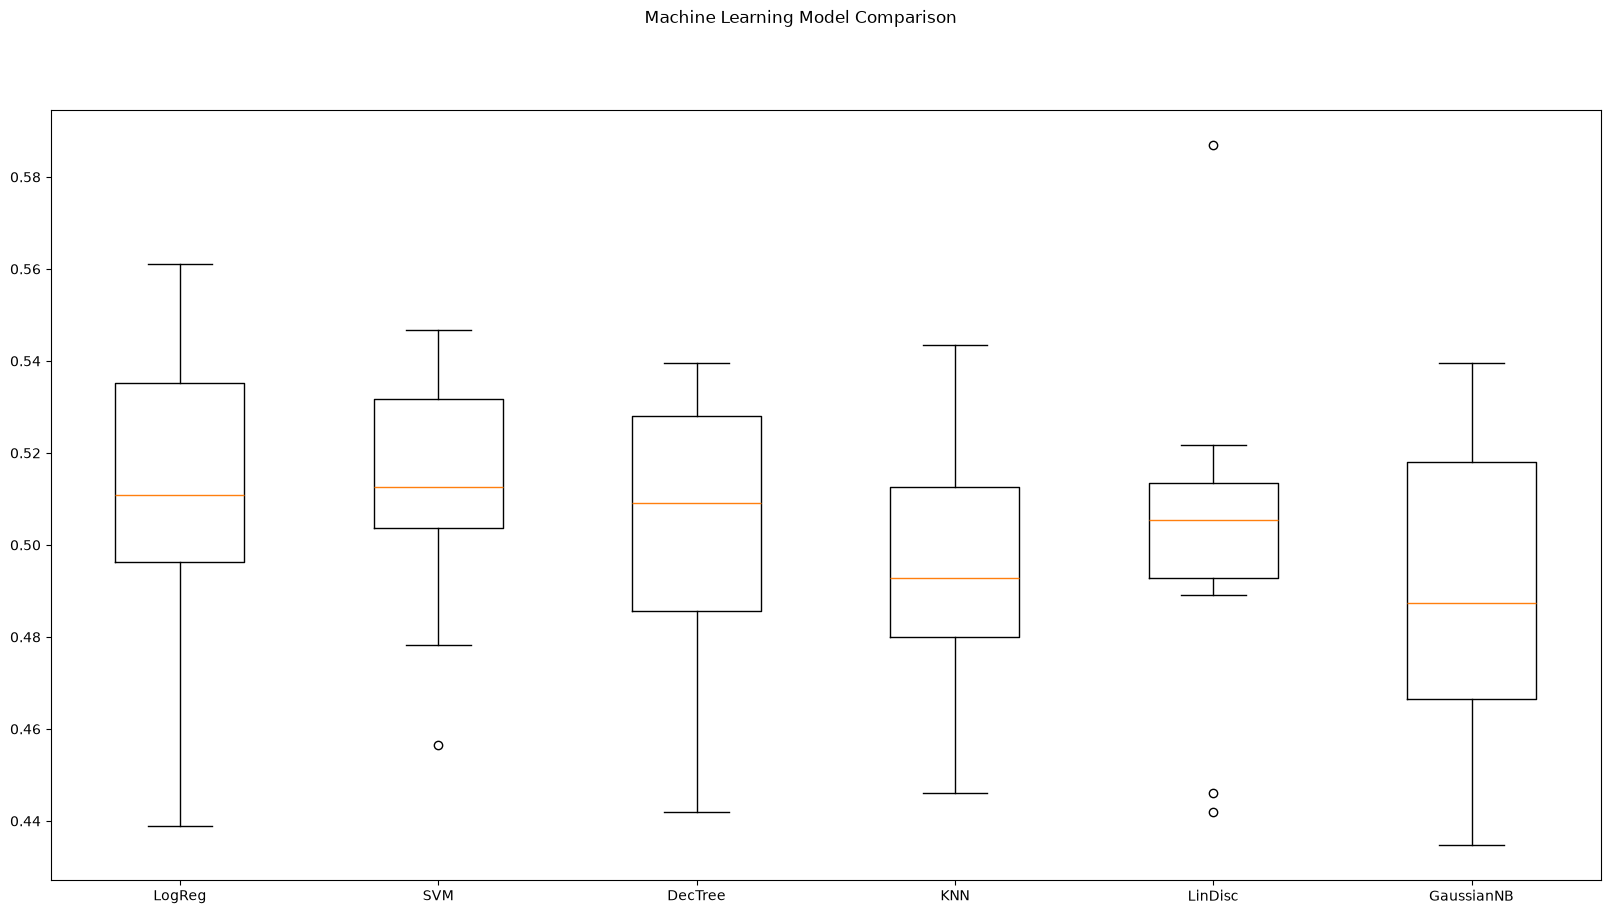

In [57]:
fig = plt.figure()
fig.suptitle('Machine Learning Model Comparison')
ax = fig.add_subplot(111)
plt.boxplot(outcome)
ax.set_xticklabels(model_names)
plt.show()